Amelorations:

1) Dans le tri de la data
Voir la correlation entre les colonnes entre elles et y (-1, 1)
Cela permet de supprimer les colonnes repetitive et de garder les colonnes quasi vide mais qui sont bien
pour predire si une personne est malade (Il faudra alors modifier comment les Nan sont gérés)

2) Keep 80% not sick, and 20% data
on v0, a lot of false positive, "sick" people are not well represented in the model

3) Dans la selection des batchs validation/ train
Employ cross validation, 4 sets of train and 1 of validation


In [5]:
import numpy as np
from pathlib import Path
from helpers import load_csv_data

# Find the data folder relative to this script
data_dir=Path("data")

# Load the datasets
x_train, x_test, y_train, train_ids, test_ids = load_csv_data(data_dir)

In [6]:
import os
# some checking
print("x_train shape :", x_train.shape)
print("y_train shape :", y_train.shape)
x_col=np.genfromtxt( os.path.join(data_dir, "x_train.csv"),delimiter=",",dtype=str,max_rows=1)
print("col of x_train",x_col)
x_col=x_col[1:]#to match the def of x_train where we have removed the first index 



x_train shape : (328135, 321)
y_train shape : (328135,)
col of x_train ['Id' '_STATE' 'FMONTH' 'IDATE' 'IMONTH' 'IDAY' 'IYEAR' 'DISPCODE' 'SEQNO'
 '_PSU' 'CTELENUM' 'PVTRESD1' 'COLGHOUS' 'STATERES' 'CELLFON3' 'LADULT'
 'NUMADULT' 'NUMMEN' 'NUMWOMEN' 'CTELNUM1' 'CELLFON2' 'CADULT' 'PVTRESD2'
 'CCLGHOUS' 'CSTATE' 'LANDLINE' 'HHADULT' 'GENHLTH' 'PHYSHLTH' 'MENTHLTH'
 'POORHLTH' 'HLTHPLN1' 'PERSDOC2' 'MEDCOST' 'CHECKUP1' 'BPHIGH4' 'BPMEDS'
 'BLOODCHO' 'CHOLCHK' 'TOLDHI2' 'CVDSTRK3' 'ASTHMA3' 'ASTHNOW' 'CHCSCNCR'
 'CHCOCNCR' 'CHCCOPD1' 'HAVARTH3' 'ADDEPEV2' 'CHCKIDNY' 'DIABETE3'
 'DIABAGE2' 'SEX' 'MARITAL' 'EDUCA' 'RENTHOM1' 'NUMHHOL2' 'NUMPHON2'
 'CPDEMO1' 'VETERAN3' 'EMPLOY1' 'CHILDREN' 'INCOME2' 'INTERNET' 'WEIGHT2'
 'HEIGHT3' 'PREGNANT' 'QLACTLM2' 'USEEQUIP' 'BLIND' 'DECIDE' 'DIFFWALK'
 'DIFFDRES' 'DIFFALON' 'SMOKE100' 'SMOKDAY2' 'STOPSMK2' 'LASTSMK2'
 'USENOW3' 'ALCDAY5' 'AVEDRNK2' 'DRNK3GE5' 'MAXDRNKS' 'FRUITJU1' 'FRUIT1'
 'FVBEANS' 'FVGREEN' 'FVORANG' 'VEGETAB1' 'EXERANY2' 'EXRACT11'

analyse of x_train


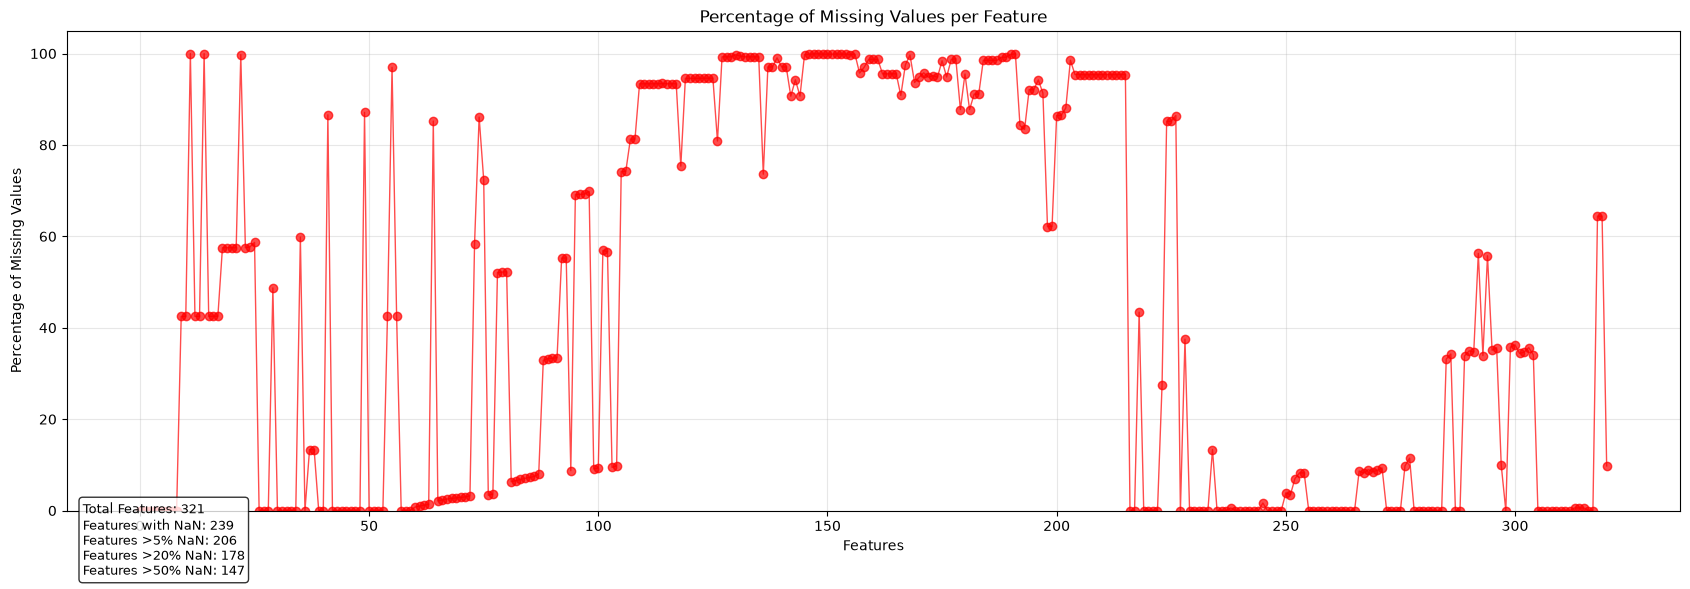

In [7]:
import matplotlib.pyplot as plt
import numpy as np


missing_percent= np.isnan(x_train).mean(axis=0)*100
feature_idx=np.arange(len(missing_percent))

#calculate statitics
n_features=len(missing_percent)
col_with_nan=missing_percent[missing_percent>0]
col_above_5=missing_percent[missing_percent>5]
col_above_20=missing_percent[missing_percent>20]
col_above_50=missing_percent[missing_percent>50]

fig, ax = plt.subplots(figsize=(17, 6))
ax.plot(feature_idx, missing_percent, marker='o', color="red",linewidth=1,alpha=0.7)
#ax.axhline(y=5, color='orange', linestyle='--', label='5% Threshold')
#ax.axhline(y=20, color='blue', linestyle='--', label='20% Threshold')
#ax.axhline(y=50, color='green', linestyle='--', label='50% Threshold')

plt.xlabel("Features")
plt.ylabel("Percentage of Missing Values")
plt.title("Percentage of Missing Values per Feature")
ax.set_ylim(0, 105)
ax.grid(alpha=0.3)
stats_text = f"Total Features: {n_features}\nFeatures with NaN: {len(col_with_nan)}\nFeatures >5% NaN: {len(col_above_5)}\nFeatures >20% NaN: {len(col_above_20)}\nFeatures >50% NaN: {len(col_above_50)}"
ax.text(0.01, 0.02, stats_text, transform=ax.transAxes, fontsize=9, verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
plt.tight_layout()
plt.show()



In [8]:
#maybe some col that we can remove 
col_above_95=missing_percent[missing_percent>95]
print("nbr of col that have more then 95 percent of missing data :"+str(len(col_above_95)))
idx_above_95=np.where(missing_percent>95)[0]
sorted_idx=idx_above_95[np.argsort(missing_percent[idx_above_95])[::-1]]
for i in sorted_idx:
    print(f"{x_col[i]}:{missing_percent[i]:.2f}%")


nbr of col that have more then 95 percent of missing data :68
LADULT:99.99%
COLGHOUS:99.99%
PCDMDECN:99.95%
ASDRVIST:99.93%
ASERVIST:99.93%
ASNOSLEP:99.90%
ASINHALR:99.85%
ASTHMED3:99.85%
ASYMPTOM:99.85%
ASACTLIM:99.85%
ASRCHKUP:99.85%
ASATTACK:99.85%
STREHAB1:99.84%
PCPSADE1:99.82%
HAREHAB1:99.76%
ASTHMAGE:99.76%
VINOCRE2:99.76%
CCLGHOUS:99.76%
HPVADSHT:99.67%
VIEYEXM2:99.43%
VIMACDG2:99.28%
VIGLUMA2:99.28%
VICTRCT4:99.28%
VIINSUR2:99.28%
VIPRFVS2:99.28%
VIREDIF3:99.28%
VIDFCLT2:99.28%
PCPSARS1:99.20%
PSATIME:99.20%
CDHELP:99.06%
LENGEXAM:98.87%
RLIVPAIN:98.72%
RDUCSTRK:98.72%
RDUCHART:98.72%
PROFEXAM:98.71%
CASTHNO2:98.53%
PSATEST1:98.52%
PCPSARE1:98.52%
PCPSADI1:98.52%
PCPSAAD2:98.51%
HPLSTTST:98.42%
HPVADVC2:97.53%
CDDISCUS:97.07%
CDSOCIAL:97.07%
CDASSIST:97.06%
CDHOUSE:97.06%
ASPUNSAF:97.00%
NUMPHON2:96.99%
HOWLONG:95.79%
CVDASPRN:95.72%
ARTHEDU:95.56%
ARTHEXER:95.56%
ARTHWGT:95.56%
ARTTODAY:95.56%
LSTBLDS3:95.52%
ADANXEV:95.41%
MISTMNT:95.41%
LSATISFY:95.41%
EMTSUPRT:95.40%
ADMOV

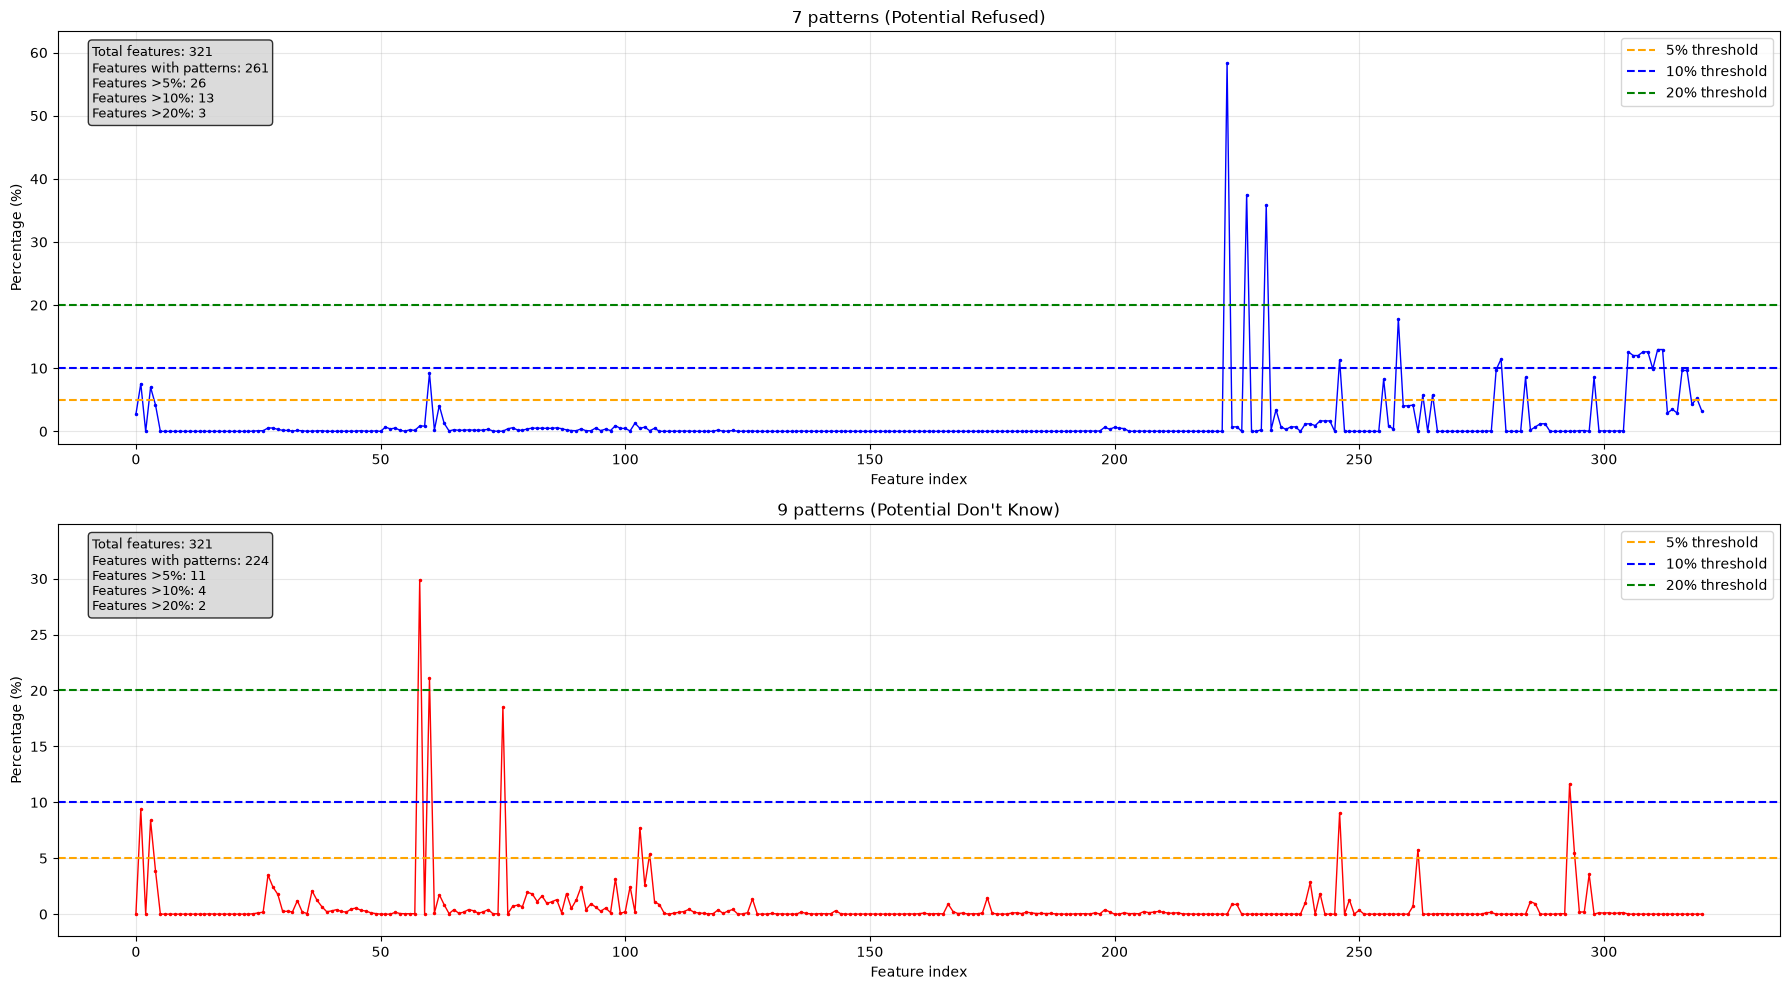

In [9]:
#now we can look at the data where we have written don't know or refused with 9 and 7 patern 

# Potential missing-value codes
dont_know_patterns = [7, 77, 777, 7777, 77777, 777777]
refused_patterns = [9, 99, 999, 9999, 99999, 999999]
# c'est l'inverse, 7 = don't know et 9 = refused

# Percentage per column
refused_percent = np.zeros(x_train.shape[1])
dont_know_percent = np.zeros(x_train.shape[1])

for code in refused_patterns:
    refused_percent += np.sum(x_train == code, axis=0)

for code in dont_know_patterns:
    dont_know_percent += np.sum(x_train == code, axis=0)

refused_percent = refused_percent / x_train.shape[0] * 100
dont_know_percent = dont_know_percent / x_train.shape[0] * 100

feature_idx = np.arange(x_train.shape[1])
n_features = x_train.shape[1]

fig, axes = plt.subplots(2, 1, figsize=(18, 10))

# Plot configurations
plots = [
    (axes[0], refused_percent, "7 patterns (Potential Refused)", "blue"),
    (axes[1], dont_know_percent, "9 patterns (Potential Don't Know)", "red")
]

for ax, percentages, title, color in plots:

    # Plot percentages
    ax.plot(feature_idx, percentages, marker='o',
            markersize=1.5, linewidth=1, color=color)

    # Threshold lines
    ax.axhline(y=5, color="orange", linestyle="--", label="5% threshold")
    ax.axhline(y=10, color="blue", linestyle="--", label="10% threshold")
    ax.axhline(y=20, color="green", linestyle="--", label="20% threshold")

    # Statistics
    n_with = np.sum(percentages > 0)
    n_above_5 = np.sum(percentages > 5)
    n_above_10 = np.sum(percentages > 10)
    n_above_20 = np.sum(percentages > 20)

    stats_text = (
        f"Total features: {n_features}\n"
        f"Features with patterns: {n_with}\n"
        f"Features >5%: {n_above_5}\n"
        f"Features >10%: {n_above_10}\n"
        f"Features >20%: {n_above_20}"
    )

    # Add statistics box inside graph
    ax.text(
        0.02, 0.97, stats_text,
        transform=ax.transAxes,
        fontsize=9,
        verticalalignment="top",
        bbox=dict(boxstyle="round", facecolor="lightgray", alpha=0.8)
    )

    ax.set_xlabel("Feature index")
    ax.set_ylabel("Percentage (%)")
    ax.set_title(title)
    ax.set_ylim(-2, max(25, np.max(percentages) + 5))
    ax.grid(alpha=0.3)
    ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

The pattern we have tested is not necessarly for teh unknown and refused questions, it could also be juste some sclar eg for the month. Need to come back later at this....
For now we can consider that we replace the 7 and 9 patterns with Nan, and removed the cols bigger the 95%. 
We need also to look at the type of input, if continous or categortical 

In [10]:
import numpy as np

def identify_feature_types(X, threshold=10):
    categorical = []
    continuous = []

    for i in range(X.shape[1]):

        # Select column and remove NaNs
        column = X[:, i]
        column = column[~np.isnan(column)]

        # Count unique values
        n_unique = len(np.unique(column))

        # Classify
        if n_unique <= threshold:
            categorical.append(i)#if use 10 or less value, then it is categorical
        else:
            continuous.append(i)

    return np.array(categorical, dtype=int), np.array(continuous, dtype=int)

In [11]:
categorical_idx, continuous_idx = identify_feature_types(x_train)

print("Categorical features:", len(categorical_idx))
print("Continuous features:", len(continuous_idx))

Categorical features: 219
Continuous features: 102


Begin with cleaning data 

In [12]:
classes, counts = np.unique(y_train, return_counts=True)

for c, count in zip(classes, counts):
    print(f"Class {c}: {count} observations ({count / len(y_train) * 100:.2f}%)")

rng = np.random.default_rng(42)

# split data 80% and 20%, training and validation set
indices = rng.permutation(len(y_train))
n_train = int(0.8 * len(y_train))
train_idx = indices[:n_train]
val_idx = indices[n_train:]
X_tr = x_train[train_idx]
X_val = x_train[val_idx]
y_tr = y_train[train_idx]
y_val = y_train[val_idx]

#find the majority class 
classes, counts = np.unique(y_tr, return_counts=True)
majority_class = classes[np.argmax(counts)]
print("Majority class:", majority_class)

#makes predictions
y_pred = np.full(len(y_val), majority_class)
accuracy = np.mean(y_pred == y_val)
print(f"Baseline accuracy: {accuracy:.2%}")#but here we always do wrong for the 1 so the baseline accuracy here si not a good crteria 

# here we see it more explicitly 
# Positive class is +1
TP = np.sum((y_val == 1) & (y_pred == 1))
FN = np.sum((y_val == 1) & (y_pred == -1))
FP = np.sum((y_val == -1) & (y_pred == 1))
TN = np.sum((y_val == -1) & (y_pred == -1))

recall = TP / (TP + FN)

print("True positives:", TP)
print("False negatives:", FN)
print("Recall:", recall)



Class -1: 299160 observations (91.17%)
Class 1: 28975 observations (8.83%)
Majority class: -1
Baseline accuracy: 91.12%
True positives: 0
False negatives: 5825
Recall: 0.0


It would be good to try to balanced the data set, using class weight, oversampling, undersampling.... 
we can do it after....

In [13]:
#but we can use a stratified training to have something a little better
#so instead of randomly splitting everyone together, we split each class separately.
#  Therefore, both subsets retain nearly the same class proportions as your original dataset
rng = np.random.default_rng(42)

train_idx = []
val_idx = []

for c in np.unique(y_train):
    idx = np.where(y_train == c)[0]
    idx = rng.permutation(idx)

    n = int(0.8 * len(idx))
    train_idx.extend(idx[:n])
    val_idx.extend(idx[n:])

train_idx = np.array(train_idx)
val_idx = np.array(val_idx)

X_tr = x_train[train_idx]
X_val = x_train[val_idx]

y_tr = y_train[train_idx]
y_val = y_train[val_idx]

for name, y in [("Train", y_tr), ("Validation", y_val)]:
    print(name)
    print("Class +1:", np.mean(y == 1) * 100, "%")
    print("Class -1:", np.mean(y == -1) * 100, "%")

Train
Class +1: 8.830207079403294 %
Class -1: 91.1697929205967 %
Validation
Class +1: 8.830207079403294 %
Class -1: 91.1697929205967 %


now we are going to handle the missing value and everything that we have anaylse before

In [14]:
X_tr_clean = X_tr.copy()
X_val_clean = X_val.copy()

patterns = [7, 77, 777, 7777, 77777, 777777,
            9, 99, 999, 9999, 99999, 999999]

X_tr_clean[np.isin(X_tr_clean, patterns)] = np.nan
X_val_clean[np.isin(X_val_clean, patterns)] = np.nan

# Percentage of missing values in each column
missing_percent = np.mean(np.isnan(X_tr_clean), axis=0) * 100 # axis 0 bc we do it by col 

# Keep columns with <= 95% missing values
keep = missing_percent <= 95

print("Original features:", X_tr_clean.shape[1])
print("Features removed:", np.sum(~keep))
print("Features kept:", np.sum(keep))

X_tr_filtered = X_tr_clean[:, keep]
X_val_filtered = X_val_clean[:, keep]
x_columns_filtered = x_col[keep]

print("Training shape:", X_tr_filtered.shape)
print("Validation shape:", X_val_filtered.shape)



Original features: 321
Features removed: 71
Features kept: 250
Training shape: (262508, 250)
Validation shape: (65627, 250)


Now we need to remplace the nan that we still have with some values using medians or modes if it is continous or categorical features. 

In [15]:
categorical_idx, continuous_idx = identify_feature_types(X_tr_filtered)

print("Categorical features:", len(categorical_idx))
print("Continuous features:", len(continuous_idx))

for i in continuous_idx:
    print(x_columns_filtered[i])

Categorical features: 169
Continuous features: 81
_STATE
IDATE
IDAY
SEQNO
_PSU
NUMADULT
HHADULT
PHYSHLTH
MENTHLTH
POORHLTH
DIABAGE2
CHILDREN
WEIGHT2
HEIGHT3
ALCDAY5
AVEDRNK2
DRNK3GE5
MAXDRNKS
FRUITJU1
FRUIT1
FVBEANS
FVGREEN
FVORANG
VEGETAB1
EXRACT11
EXEROFT1
EXERHMM1
EXRACT21
EXEROFT2
EXERHMM2
STRENGTH
FLSHTMY2
HIVTSTD3
BLDSUGAR
FEETCHK2
DOCTDIAB
CHKHEMO3
FEETCHK
LONGWTCH
SCNTWRK1
SCNTLWK1
_STSTR
_STRWT
_RAWRAKE
_WT2RAKE
_CLLCPWT
_DUALCOR
_LLCPWT
_AGEG5YR
_AGE80
HTIN4
HTM4
WTKG3
_BMI5
DROCDY3_
_DRNKWEK
FTJUDA1_
FRUTDA1_
BEANDAY_
GRENDAY_
ORNGDAY_
VEGEDA1_
_FRUTSUM
_VEGESUM
METVL11_
METVL21_
MAXVO2_
FC60_
PADUR1_
PADUR2_
PAFREQ1_
PAFREQ2_
_MINAC11
_MINAC21
STRFREQ_
PAMIN11_
PAMIN21_
PA1MIN_
PAVIG11_
PAVIG21_
PA1VIGM_


In [16]:
#we now need to remplace the nan, for thsi we can do a function that remplace nan by mode for categortical 
#features and median for continous ones 
def impute_missing(X_train, X_val, categorical_idx):

    X_train_new = X_train.copy()
    X_val_new = X_val.copy()

    for i in range(X_train.shape[1]):

        column = X_train[:, i]
        observed = column[~np.isnan(column)]

        # If the entire column is missing
        if len(observed) == 0:
            fill_value = 0

        # Categorical feature: mode
        elif i in categorical_idx:
            values, counts = np.unique(observed, return_counts=True)
            fill_value = values[np.argmax(counts)]

        # Continuous feature: median
        else:
            fill_value = np.median(observed)

        # Fill missing values in both datasets
        X_train_new[np.isnan(X_train_new[:, i]), i] = fill_value
        X_val_new[np.isnan(X_val_new[:, i]), i] = fill_value

    return X_train_new, X_val_new

In [17]:
X_tr_imputed, X_val_imputed = impute_missing(
    X_tr_filtered,
    X_val_filtered,
    categorical_idx
)
#just to verify 
print("NaNs in training:", np.isnan(X_tr_imputed).sum())
print("NaNs in validation:", np.isnan(X_val_imputed).sum())

NaNs in training: 0
NaNs in validation: 0


we can now Standardize the features so taht they all have the same scale 

In [18]:
# Compute statistics from training data
means = np.mean(X_tr_imputed, axis=0)
stds = np.std(X_tr_imputed, axis=0)

# Avoid division by zero for constant features
stds[stds == 0] = 1

# Standardize both sets
X_tr_scaled = (X_tr_imputed - means) / stds
X_val_scaled = (X_val_imputed - means) / stds

fisrt test done with ridge regression, need to be continued 

In [19]:
from implementations import *
# Add intercept
tx_tr = np.column_stack((
    np.ones(X_tr_scaled.shape[0]),
    X_tr_scaled
))

tx_val = np.column_stack((
    np.ones(X_val_scaled.shape[0]),
    X_val_scaled
))

# Train ridge regression
lambda_ = 0.01

w = ridge_regression(y_tr, tx_tr, lambda_)

print("Shape of w:", w.shape)

Shape of w: (251,)


In [20]:
# 1. Prédictions de la régression Ridge
y_scores = tx_val @ w

# 2. Transformation des prédictions en classes -1 ou 1
y_pred = np.where(y_scores >= 0, 1, -1)

# 3. Calcul de la matrice de confusion
TP = np.sum((y_val == 1) & (y_pred == 1))
TN = np.sum((y_val == -1) & (y_pred == -1))
FP = np.sum((y_val == -1) & (y_pred == 1))
FN = np.sum((y_val == 1) & (y_pred == -1))

# 4. Calcul des métriques
accuracy = (TP + TN) / (TP + TN + FP + FN)

precision = TP / (TP + FP) if (TP + FP) > 0 else 0

recall = TP / (TP + FN) if (TP + FN) > 0 else 0

f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0

specificity = TN / (TN + FP) if (TN + FP) > 0 else 0

# 5. Affichage des résultats
print("===== RIDGE REGRESSION - VALIDATION =====")
print(f"Accuracy    : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precision   : {precision:.4f}")
print(f"Recall      : {recall:.4f}")
print(f"F1-score    : {f1:.4f}")
print(f"Specificity : {specificity:.4f}")

print("\n===== CONFUSION MATRIX =====")
print(f"True Positives  (TP): {TP}")
print(f"True Negatives  (TN): {TN}")
print(f"False Positives (FP): {FP}")
print(f"False Negatives (FN): {FN}")

print("\nConfusion matrix:")
print("                 Predicted -1    Predicted 1")
print(f"Actual -1        {TN:12d}    {FP:11d}")
print(f"Actual  1        {FN:12d}    {TP:11d}")

print(f"\nTotal validation samples: {len(y_val)}")


===== RIDGE REGRESSION - VALIDATION =====
Accuracy    : 0.9141 (91.41%)
Precision   : 0.6632
Recall      : 0.0557
F1-score    : 0.1028
Specificity : 0.9973

===== CONFUSION MATRIX =====
True Positives  (TP): 323
True Negatives  (TN): 59668
False Positives (FP): 164
False Negatives (FN): 5472

Confusion matrix:
                 Predicted -1    Predicted 1
Actual -1               59668            164
Actual  1                5472            323

Total validation samples: 65627


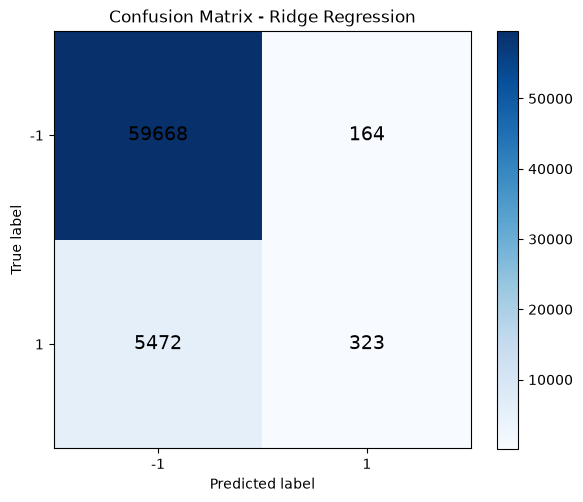

In [21]:
confusion_matrix = np.array([
    [TN, FP],
    [FN, TP]
])

fig, ax = plt.subplots(figsize=(6, 5))

im = ax.imshow(confusion_matrix, cmap="Blues")

ax.set_xticks([0, 1], labels=["-1", "1"])
ax.set_yticks([0, 1], labels=["-1", "1"])

ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_title("Confusion Matrix - Ridge Regression")

for i in range(2):
    for j in range(2):
        ax.text(j, i, str(confusion_matrix[i, j]),
                ha="center", va="center",
                fontsize=14)

plt.colorbar(im)
plt.tight_layout()
plt.show()


Applying the amelioration

In [22]:
X = np.asarray(x_train, dtype=float).copy()
y = np.asarray(y_train).reshape(-1).astype(int)
names = np.asarray(x_col, dtype=str)
assert X.shape[1] == len(names) and len(y) == len(X)
patterns = [7,77,777,7777,77777,777777,9,99,999,9999,99999,999999]
X[np.isin(X, patterns)] = np.nan
print('After V1-style replacement:', X.shape, 'NaN share:', f'{np.isnan(X).mean():.2%}')
print('Labels:', dict(zip(*np.unique(y, return_counts=True))))

After V1-style replacement: (328135, 321) NaN share: 46.88%
Labels: {np.int64(-1): np.int64(299160), np.int64(1): np.int64(28975)}


Correlation with illness and between features

For each column we calculate two signals: correlation of its observed values with y, and correlation of its missingness indicator with y. A sparse column can therefore remain useful. Pairwise feature redundancy is checked on overlapping observed rows. These plots are exploratory only: final feature selection is recomputed on the training part of each cross-validation fold.

In [49]:
def abs_corr(a, b, min_pairs=30):
    valid = np.isfinite(a) & np.isfinite(b)
    if valid.sum() < min_pairs: return 0.0
    aa, bb = a[valid], b[valid]
    if np.std(aa) < 1e-12 or np.std(bb) < 1e-12: return 0.0
    return float(abs(np.corrcoef(aa, bb)[0, 1]))

def feature_selection(Xtr, ytr, redundancy=0.98, min_pairs=40,
                      max_features=200, min_observed=30):
    # Missingness is potentially informative: never discard only for 95% NaN.
    n, p = Xtr.shape
    scores = np.zeros(p)
    value_scores = np.zeros(p)
    missing_scores = np.zeros(p)
    for j in range(p):
        observed = np.isfinite(Xtr[:, j])
        if observed.sum() >= min_observed:
            value_scores[j] = abs_corr(Xtr[:, j], ytr, min_pairs=min_pairs)
        if observed.any() and (~observed).any():
            missing_scores[j] = abs_corr(observed.astype(float), ytr, min_pairs=min_pairs)
        scores[j] = max(value_scores[j], missing_scores[j])
    order = np.argsort(-scores, kind='stable')
    chosen = []
    for j in order:
        if scores[j] <= 0: continue
        if any(abs_corr(Xtr[:, j], Xtr[:, k], min_pairs=min_pairs) >= redundancy
               for k in chosen):
            continue
        chosen.append(int(j))
        if len(chosen) >= max_features: break
    return np.array(chosen, dtype=int), scores, value_scores, missing_scores


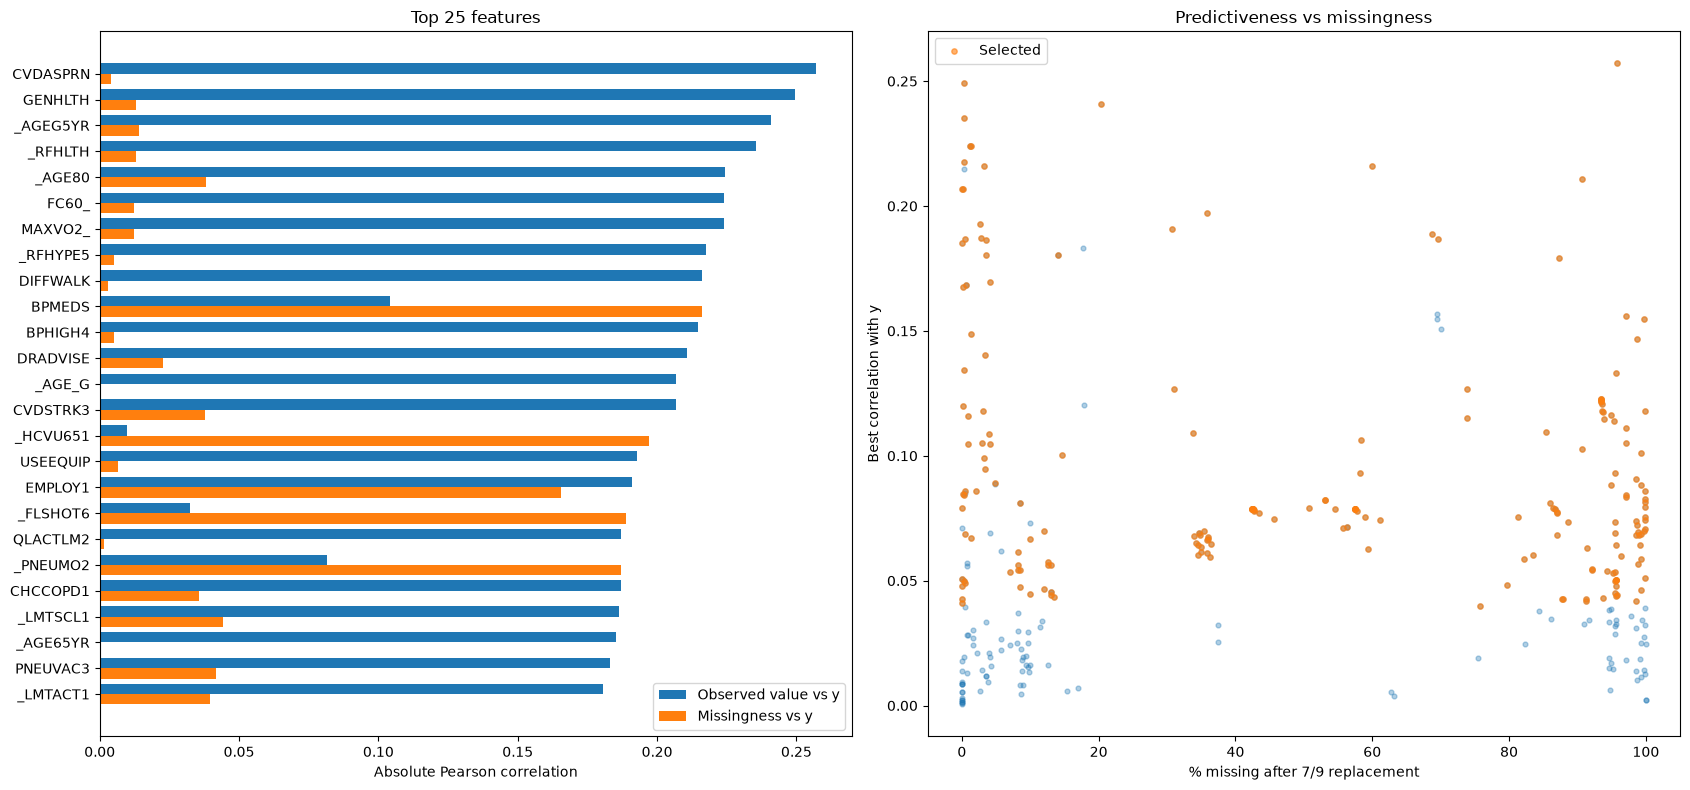

Selected: 200 / 321
CVDASPRN                       value=0.257 missing=0.004 NaN=95.7%
GENHLTH                        value=0.249 missing=0.013 NaN=0.3%
_AGEG5YR                       value=0.241 missing=0.014 NaN=20.4%
_RFHLTH                        value=0.235 missing=0.013 NaN=0.3%
_AGE80                         value=0.224 missing=0.038 NaN=1.3%
FC60_                          value=0.224 missing=0.012 NaN=1.2%
MAXVO2_                        value=0.224 missing=0.012 NaN=1.2%
_RFHYPE5                       value=0.218 missing=0.005 NaN=0.3%
DIFFWALK                       value=0.216 missing=0.003 NaN=3.3%
BPMEDS                         value=0.104 missing=0.216 NaN=59.9%
BPHIGH4                        value=0.215 missing=0.005 NaN=0.3%
DRADVISE                       value=0.211 missing=0.023 NaN=90.7%
_AGE_G                         value=0.207 missing=0.000 NaN=0.0%
CVDSTRK3                       value=0.207 missing=0.038 NaN=0.2%
_HCVU651                       value=0.010 missing=0

In [50]:
import matplotlib.pyplot as plt
chosen_all, score_all, value_all, missing_all = feature_selection(X, y)
missing_pct = np.isnan(X).mean(axis=0) * 100
rank = np.argsort(-score_all)[:25]
fig, ax = plt.subplots(1, 2, figsize=(17, 8))
ax[0].barh(np.arange(len(rank))-.2, value_all[rank], height=.4, label='Observed value vs y')
ax[0].barh(np.arange(len(rank))+.2, missing_all[rank], height=.4, label='Missingness vs y')
ax[0].set_yticks(np.arange(len(rank)), names[rank]); ax[0].invert_yaxis()
ax[0].set_xlabel('Absolute Pearson correlation'); ax[0].set_title('Top 25 features'); ax[0].legend()
ax[1].scatter(missing_pct, score_all, alpha=.35, s=12)
ax[1].scatter(missing_pct[chosen_all], score_all[chosen_all], alpha=.6, s=15, label='Selected')
ax[1].set(xlabel='% missing after 7/9 replacement', ylabel='Best correlation with y', title='Predictiveness vs missingness')
ax[1].legend(); plt.tight_layout(); plt.show()
print('Selected:', len(chosen_all), '/', X.shape[1])
for j in rank[:20]: print(f'{names[j]:30s} value={value_all[j]:.3f} missing={missing_all[j]:.3f} NaN={missing_pct[j]:.1f}%')

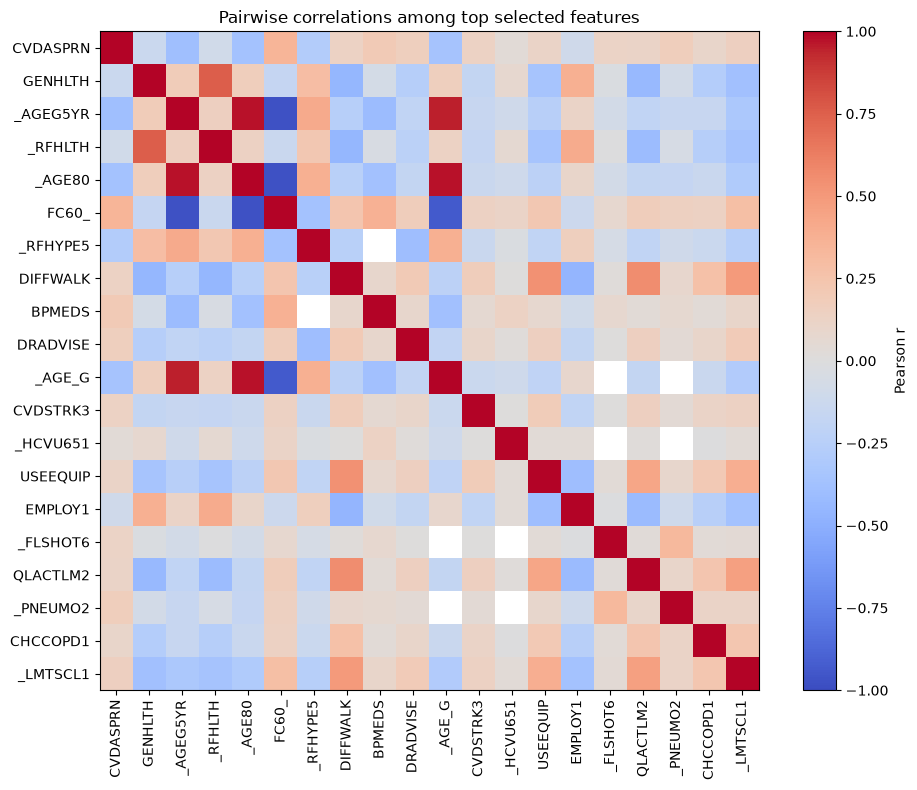

In [51]:
# Redundancy heatmap: strongest selected features, using pairwise observed values
strong = chosen_all[:min(20, len(chosen_all))]
R = np.eye(len(strong))
for a in range(len(strong)):
    for b in range(a):
        aa, bb = X[:,strong[a]], X[:,strong[b]]
        mask = np.isfinite(aa) & np.isfinite(bb)
        if mask.sum() >= 40 and np.std(aa[mask]) > 1e-12 and np.std(bb[mask]) > 1e-12:
            R[a,b] = R[b,a] = np.corrcoef(aa[mask],bb[mask])[0,1]
        else: R[a,b] = R[b,a] = np.nan
fig, ax = plt.subplots(figsize=(10,8))
im = ax.imshow(R, vmin=-1,vmax=1,cmap='coolwarm')
ax.set_xticks(range(len(strong)),names[strong],rotation=90)
ax.set_yticks(range(len(strong)),names[strong]); fig.colorbar(im,ax=ax,label='Pearson r')
ax.set_title('Pairwise correlations among top selected features');plt.tight_layout();plt.show()

Missing values, 80/20 resampling, and 5-fold validation

All learned preprocessing is fitted inside each training fold. Missing values use mode for categorical variables, median for continuous variables (as in V1), and we append a missingness indicator for every selected feature. We then standardize using training statistics only. Only training observations are resampled to 80% -1 and 20% +1; validation stays at its natural prevalence.

In [52]:
def fit_transform_fold(Xtr, Xva, chosen):
    A, B = Xtr[:, chosen].copy(), Xva[:, chosen].copy()
    missing_A = ~np.isfinite(A)
    missing_B = ~np.isfinite(B)
    categorical_idx, _ = identify_feature_types(A)
    categorical_idx = set(categorical_idx)
    medians = np.zeros(A.shape[1])
    for j in range(A.shape[1]):
        obs = A[np.isfinite(A[:, j]), j]
        if len(obs) == 0: medians[j] = 0.0
        elif j in categorical_idx:
            vals, counts = np.unique(obs, return_counts=True)
            medians[j] = vals[np.argmax(counts)]
        else: medians[j] = np.median(obs)
    A = np.where(missing_A, medians, A)
    B = np.where(missing_B, medians, B)
    # Include missingness indicators, useful especially for sparse features.
    A = np.column_stack([A, missing_A.astype(float)])
    B = np.column_stack([B, missing_B.astype(float)])
    mean, std = A.mean(axis=0), A.std(axis=0)
    std[std < 1e-12] = 1.0
    return (A - mean) / std, (B - mean) / std

def stratified_folds(y, n_splits=5, seed=42):
    rng = np.random.default_rng(seed)
    bins = [[] for _ in range(n_splits)]
    for cls in np.unique(y):
        indices = rng.permutation(np.flatnonzero(y == cls))
        for k, chunk in enumerate(np.array_split(indices, n_splits)):
            bins[k].extend(chunk.tolist())
    for k in range(n_splits):
        val = np.array(sorted(bins[k]), dtype=int)
        train = np.setdiff1d(np.arange(len(y)), val, assume_unique=True)
        yield train, val

def balance_80_20(indices, y, seed=42, positive_share=0.10): # change the positive_share to 0.20 to have a better balance between the two classes
    rng = np.random.default_rng(seed)
    neg = indices[y[indices] == -1]
    pos = indices[y[indices] == 1]
    # Under-sample only the class that is over-represented relative to target.
    if not len(pos) or not len(neg): raise ValueError('Both classes required')
    if len(pos) / len(indices) < positive_share:
        target_neg = min(len(neg), int(len(pos) * (1-positive_share)/positive_share))
        neg = rng.choice(neg, size=target_neg, replace=False)
    else:
        target_pos = min(len(pos), int(len(neg) * positive_share/(1-positive_share)))
        pos = rng.choice(pos, size=target_pos, replace=False)
    return rng.permutation(np.r_[neg, pos])


Cross-validation results

Each of the five folds is used once for validation. The plot below shows per-fold precision, recall and false positives, plus the combined out-of-fold confusion matrix. A 0 decision threshold is retained from V1 for comparability; adjust it separately if false positives are too high.

In [58]:
# Hyperparameters
lambda_ = 0.1
threshold = -0.6  # Lower threshold to detect more sick patients


def metrics(y_true, y_pred):
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    fp = int(np.sum((y_true == -1) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == -1)))
    tn = int(np.sum((y_true == -1) & (y_pred == -1)))

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    specificity = tn / (tn + fp) if tn + fp else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0

    return dict(
        TP=tp, FP=fp, FN=fn, TN=tn,
        precision=precision,
        recall=recall,
        specificity=specificity,
        f1=f1,
        accuracy=(tp + tn) / len(y_true)
    )


results = []
oof_scores = np.full(len(y), np.nan)

for fold, (tr_idx, va_idx) in enumerate(stratified_folds(y), start=1):

    # 1. Feature selection
    selected, scores, value_scores, missing_scores = feature_selection(
        X[tr_idx], y[tr_idx]
    )

    # 2. Balance training data (80% healthy, 20% sick)
    balanced_idx = balance_80_20(tr_idx, y, seed=42 + fold)

    # 3. Handle NaNs and standardize features
    Xtr, Xva = fit_transform_fold(
        X[balanced_idx], X[va_idx], selected
    )

    # 4. Add intercept column
    Xtr_ridge = np.column_stack([
        np.ones(len(Xtr)), Xtr
    ])

    Xva_ridge = np.column_stack([
        np.ones(len(Xva)), Xva
    ])

    # 5. Train using YOUR ridge_regression function
    w = ridge_regression(
        y[balanced_idx],
        Xtr_ridge,
        lambda_
    )

    # 6. Predict continuous Ridge scores
    score = Xva_ridge @ w
    oof_scores[va_idx] = score

    # 7. Apply classification threshold
    y_pred = np.where(score >= threshold, 1, -1)

    # 8. Evaluate
    row = metrics(y[va_idx], y_pred)
    results.append(row)

    print(
        f'Fold {fold}: '
        f'features={len(selected)}, '
        f'train +1={np.mean(y[balanced_idx] == 1):.1%}, '
        f'val +1={np.mean(y[va_idx] == 1):.1%}, '
        f'FP={row["FP"]}, '
        f'FN={row["FN"]}, '
        f'precision={row["precision"]:.3f}, '
        f'recall={row["recall"]:.3f}, '
        f'F1={row["f1"]:.3f}'
    )


print('\nAverage validation metrics:')

for key in ['accuracy', 'precision', 'recall', 'specificity', 'f1']:
    print(
        f'{key}: '
        f'{np.mean([r[key] for r in results]):.3f} '
        f'± {np.std([r[key] for r in results]):.3f}'
    )

print(
    '\nTotal out-of-fold confusion:',
    metrics(y, np.where(oof_scores >= threshold, 1, -1))
)


Fold 1: features=200, train +1=10.0%, val +1=8.8%, FP=15586, FN=1049, precision=0.233, recall=0.819, F1=0.363
Fold 2: features=200, train +1=10.0%, val +1=8.8%, FP=15724, FN=1080, precision=0.231, recall=0.814, F1=0.359
Fold 3: features=200, train +1=10.0%, val +1=8.8%, FP=15384, FN=1134, precision=0.233, recall=0.804, F1=0.361
Fold 4: features=200, train +1=10.0%, val +1=8.8%, FP=15798, FN=1083, precision=0.230, recall=0.813, F1=0.358
Fold 5: features=200, train +1=10.0%, val +1=8.8%, FP=15784, FN=1052, precision=0.231, recall=0.818, F1=0.360

Average validation metrics:
accuracy: 0.745 ± 0.002
precision: 0.231 ± 0.001
recall: 0.814 ± 0.005
specificity: 0.738 ± 0.003
f1: 0.360 ± 0.002

Total out-of-fold confusion: {'TP': 23577, 'FP': 78276, 'FN': 5398, 'TN': 220884, 'precision': 0.23148066330888634, 'recall': 0.8137014667817084, 'specificity': 0.7383473726434016, 'f1': 0.3604274314366955, 'accuracy': 0.7450012951986226}


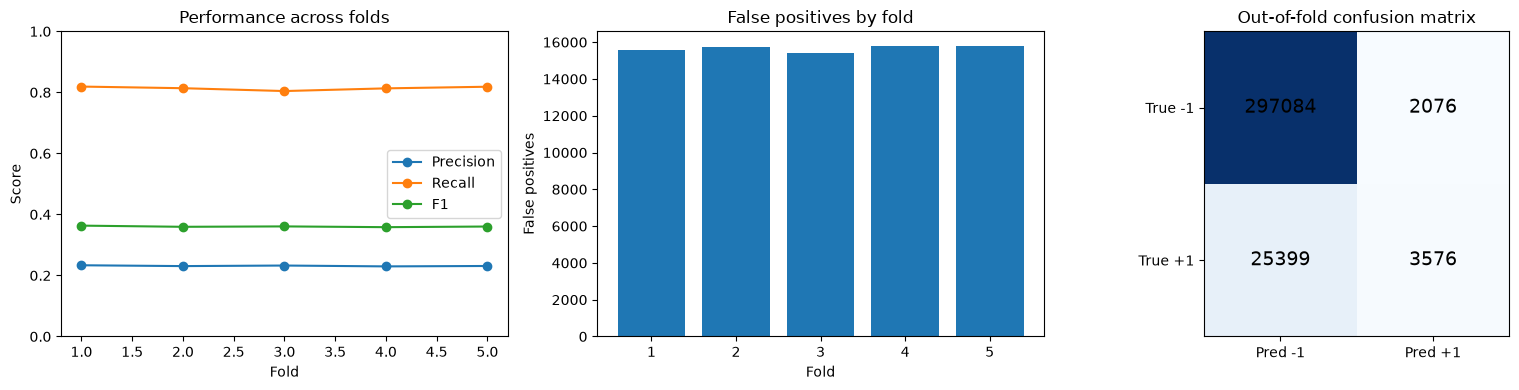

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4))

f = np.arange(1, len(results) + 1)

# 1. Precision, Recall, F1 across folds
axs[0].plot(f, [r['precision'] for r in results],
            marker='o', label='Precision')
axs[0].plot(f, [r['recall'] for r in results],
            marker='o', label='Recall')
axs[0].plot(f, [r['f1'] for r in results],
            marker='o', label='F1')

axs[0].set(
    xlabel='Fold',
    ylabel='Score',
    ylim=(0, 1),
    title='Performance across folds'
)
axs[0].legend()
axs[0].grid(alpha=0.3)

# 2. False positives AND false negatives
width = 0.35

axs[1].bar(f - width/2, [r['FP'] for r in results],
           width, label='False positives')
axs[1].bar(f + width/2, [r['FN'] for r in results],
           width, label='False negatives')

axs[1].set(
    xlabel='Fold',
    ylabel='Number of patients',
    title='Classification errors by fold'
)
axs[1].legend()

# 3. Confusion matrix using the CURRENT threshold
all_metrics = metrics(
    y,
    np.where(oof_scores >= threshold, 1, -1)
)

cm = np.array([
    [all_metrics['TN'], all_metrics['FP']],
    [all_metrics['FN'], all_metrics['TP']]
])

axs[2].imshow(cm, cmap='Blues')

for i in range(2):
    for j in range(2):
        axs[2].text(
            j, i, str(cm[i, j]),
            ha='center',
            va='center',
            fontsize=14
        )

axs[2].set_xticks([0, 1], ['Pred -1', 'Pred +1'])
axs[2].set_yticks([0, 1], ['True -1', 'True +1'])
axs[2].set_title(f'Confusion matrix (threshold={threshold})')

plt.tight_layout()
plt.show()

print("Current threshold:", threshold)
print("TP:", all_metrics['TP'])
print("FP:", all_metrics['FP'])
print("FN:", all_metrics['FN'])
print("TN:", all_metrics['TN'])
print("Recall:", round(all_metrics['recall'], 3))
print("Precision:", round(all_metrics['precision'], 3))

What hyperparameters to change for better results?
1) y_pred threshold for switching to 1 or -1
2) lambda value for ridge regression (regularization of the logistic regression, try 0.0001, 0.01, 0.1)
3) proportionnality of sick/ non sick in training batches (10/90, 20/80)


Now lets extract prediction for x_test

In [62]:

from helpers import create_csv_submission

# 1. Hyperparameters chosen during validation
lambda_ = 0.01
threshold = -0.6

# 2. Prepare test data with the SAME NaN convention as V2
X_test = np.asarray(x_test, dtype=float).copy()

patterns = [7, 77, 777, 7777, 77777, 777777,
            9, 99, 999, 9999, 99999, 999999]

X_test[np.isin(X_test, patterns)] = np.nan

# 3. Select features using all training data
selected, scores, value_scores, missing_scores = feature_selection(X, y)

# 4. Balance the full training dataset
all_indices = np.arange(len(y))
balanced_idx = balance_80_20(all_indices, y, seed=42)

# 5. Apply the same preprocessing to train and test
Xtr, Xte = fit_transform_fold(
    X[balanced_idx],
    X_test,
    selected
)

# 6. Add intercept columns
Xtr_ridge = np.column_stack([np.ones(len(Xtr)), Xtr])
Xte_ridge = np.column_stack([np.ones(len(Xte)), Xte])

# 7. Train final model
w = ridge_regression(
    y[balanced_idx],
    Xtr_ridge,
    lambda_
)

# 8. Predict test scores and labels
test_scores = Xte_ridge @ w
y_test_pred = np.where(test_scores >= threshold, 1, -1)

# 9. Create submission folder and CSV
submission_dir = Path("submissions")
submission_dir.mkdir(parents=True, exist_ok=True)

submission_path = submission_dir / "submission_ridge_v1.csv"

assert len(test_ids) == len(y_test_pred)
assert np.all(np.isin(y_test_pred, [-1, 1]))

create_csv_submission(
    test_ids,
    y_test_pred,
    str(submission_path)
)

print("Submission created:", submission_path)
print("Number of predictions:", len(y_test_pred))
print("Predicted sick:", np.mean(y_test_pred == 1))
print("Predicted healthy:", np.mean(y_test_pred == -1))


Submission created: submissions\submission_ridge_v1.csv
Number of predictions: 109379
Predicted sick: 0.194680880242094
Predicted healthy: 0.805319119757906
